<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/07.%20Support%20Vector%20Machines%20and%20Kernel%20Methods/ch07_svm_kernels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7: Support Vector Machines and Kernel Methods

Support vector machines (SVMs) approach classification geometrically rather than probabilistically: instead of modelling $P(Y=1\mid X)$, they search for the hyperplane that **maximises the margin** between classes. Combined with the **kernel trick**, SVMs can also draw highly non-linear decision boundaries without ever explicitly computing a high-dimensional feature map. This chapter builds SVM intuition from the margin up, explores kernel functions, hyperparameter tuning, high-dimensional data, and a full evaluation toolkit.

**What this notebook covers**

1. **Introduction to SVMs**: the margin-maximisation idea, support vectors, soft margins, classification and regression (SVR)
2. **Kernel functions**: linear, polynomial, and RBF kernels and how they warp decision boundaries, with a from-scratch kernel-trick verification
3. **Tuning SVM parameters**: `C` and kernel-specific hyperparameters via grid search
4. **SVMs in high-dimensional spaces**: a 1000-feature synthetic dataset, the curse of dimensionality, PCA for visualisation
5. **Evaluating SVM models**: classification report, ROC/AUC
6. **Practical exercises** (classifier, grid-search tuning, decision-boundary visualisation)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 7. The book's datasets and seed (`random_state=2024`) are reproduced; each recipe is extended with derivations, additional verification, and extra experiments beyond the book's own code.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import time

from sklearn.datasets import load_iris, load_breast_cancer, make_classification, make_circles
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                              mean_squared_error, roc_curve, auc)
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

np.random.seed(2024)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.9.1
NumPy version:        2.5.3
pandas version:       3.0.5


## 1. Introduction to SVMs

An SVM looks for the **hyperplane** that separates two classes while maximising the **margin** — the distance between the hyperplane and the nearest training points of each class, called the **support vectors**. Only these points determine the boundary; every other training point could move (without crossing the margin) and the boundary would stay the same. Maximising the margin is, intuitively, choosing the "most confident" separating line rather than any line that merely happens to separate the training data.

For a linearly separable dataset, the SVM optimisation problem is

$$\min_{\mathbf w,b}\ \tfrac12\lVert\mathbf w\rVert^2 \quad\text{subject to}\quad y_i(\mathbf w\cdot\mathbf x_i+b)\ge1\ \ \forall i$$

Real data is rarely perfectly separable, so scikit-learn's `SVC` solves the **soft-margin** version, which tolerates violations via slack variables $\xi_i\ge0$ and a penalty `C`:

$$\min_{\mathbf w,b,\xi}\ \tfrac12\lVert\mathbf w\rVert^2+C\sum_i\xi_i \quad\text{subject to}\quad y_i(\mathbf w\cdot\mathbf x_i+b)\ge1-\xi_i,\ \xi_i\ge0$$

Large `C` penalises margin violations heavily (narrow margin, fits training data closely, can overfit); small `C` tolerates more violations for a wider, more general margin.

### 1.1 Linear-kernel SVM on Iris

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)
y_pred = svm_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()
print(f"Accuracy: {accuracy:.4f}")
print(report_df.round(3))
print(f"\nNumber of support vectors per class: {svm_classifier.n_support_} "
      f"(out of {len(X_train)} training points, {svm_classifier.n_support_.sum()} total, "
      f"{100*svm_classifier.n_support_.sum()/len(X_train):.1f}% of the training set)")

Accuracy: 0.9333
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.9090  0.8330    0.8700  12.0000
2                0.8750  0.9330    0.9030  15.0000
accuracy         0.9330  0.9330    0.9330   0.9330
macro avg        0.9280  0.9220    0.9240  45.0000
weighted avg     0.9340  0.9330    0.9330  45.0000

Number of support vectors per class: [ 3 10  8] (out of 105 training points, 21 total, 20.0% of the training set)


Even the default linear kernel does very well on this well-separated dataset. The support-vector count shows directly how few points actually define the boundary — a hallmark of SVMs' sparse solutions: most training points lie safely on the correct side of the margin and could be removed without changing the fitted boundary at all.

### 1.2 A regression example (SVR)

SVMs extend to regression (SVR) by finding a function that keeps as many points as possible within an $\varepsilon$-wide tube around the prediction, only penalising points outside that tube.

In [3]:
svm_regressor = SVR(kernel='rbf')
svm_regressor.fit(X_train[:, :2], y_train)
y_pred_reg = svm_regressor.predict(X_test[:, :2])

mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.4f}")
print(f"(Note: we're regressing an integer class label 0/1/2 on just 2 features here, "
      f"purely to illustrate SVR mechanics -- this is not a sensible real regression target.)")

MSE: 0.2037
(Note: we're regressing an integer class label 0/1/2 on just 2 features here, purely to illustrate SVR mechanics -- this is not a sensible real regression target.)


### 1.3 Visualising the SVM decision boundary

We train a fresh SVR-based boundary on the first two features only, so it can be plotted in 2-D (reproducing the book's recipe, using `DecisionBoundaryDisplay`).

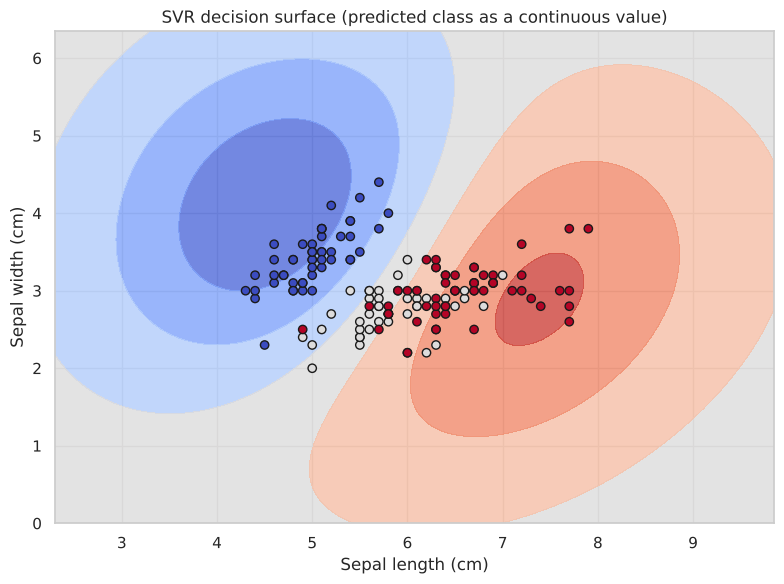

In [4]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
grid_points = np.c_[xx.ravel(), yy.ravel(), np.zeros((xx.ravel().shape[0], 2))]

fig, ax = plt.subplots(figsize=(8, 6))
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor, grid_points[:, :2], response_method="predict", plot_method="contourf",
    cmap=plt.cm.coolwarm, alpha=0.8, ax=ax)
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
ax.set_title("SVR decision surface (predicted class as a continuous value)")
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
plt.tight_layout()
plt.show()

Because SVR is a regression model here, the shading is a continuous surface (predicted "class value") rather than hard regions — darker/lighter areas correspond to the model's smooth interpolation between the three integer class labels, not a true classification boundary. A genuine classification boundary (next section) produces sharp regions instead.

### 1.4 Hands-on checklist
1. Standardise features where scale varies widely (SVMs are distance-based, like KNN).
2. Fit `SVC(kernel=...)` for classification or `SVR(kernel=...)` for regression.
3. Check `n_support_` to see how sparse the solution is.
4. Tune `C` to balance margin width against training-data fit.

## 2. Kernel Functions and Their Applications

A **kernel function** $K(\mathbf x_i,\mathbf x_j)$ computes the dot product of two points *as if* they had been mapped into a higher-dimensional feature space $\phi(\cdot)$, without ever computing $\phi$ explicitly — the **kernel trick**:

$$K(\mathbf x_i,\mathbf x_j)=\phi(\mathbf x_i)\cdot\phi(\mathbf x_j)$$

| Kernel | Formula | Use case |
|:--|:--|:--|
| Linear | $K=\mathbf x_i\cdot\mathbf x_j$ | Linearly separable data |
| Polynomial | $K=(\gamma\,\mathbf x_i\cdot\mathbf x_j+r)^d$ | Feature-interaction / polynomial relationships |
| RBF (Gaussian) | $K=\exp(-\gamma\lVert\mathbf x_i-\mathbf x_j\rVert^2)$ | Complex, non-linear relationships (most common default) |

### 2.1 Verifying the kernel trick by hand

We confirm, on a tiny example, that the kernel formula really does equal the dot product in the mapped space — the theoretical justification for why it works at all.

In [5]:
# For a degree-2 polynomial kernel with gamma=1, r=1 and 2 input features,
# the explicit feature map is phi(x1,x2) = [1, sqrt(2)x1, sqrt(2)x2, x1^2, sqrt(2)x1x2, x2^2]
def phi_poly2(x):
    x1, x2 = x
    return np.array([1, np.sqrt(2)*x1, np.sqrt(2)*x2, x1**2, np.sqrt(2)*x1*x2, x2**2])

rng = np.random.default_rng(2024)
a_pt, b_pt = rng.normal(size=2), rng.normal(size=2)

kernel_value = polynomial_kernel([a_pt], [b_pt], degree=2, gamma=1, coef0=1)[0, 0]
explicit_dot = phi_poly2(a_pt) @ phi_poly2(b_pt)

print(f"Point a: {a_pt.round(3)}, Point b: {b_pt.round(3)}")
print(f"Kernel K(a,b) computed directly:         {kernel_value:.6f}")
print(f"phi(a) . phi(b) in the explicit 6-D map: {explicit_dot:.6f}")
print(f"Match: {np.isclose(kernel_value, explicit_dot)}")

Point a: [1.029 1.642], Point b: [ 1.147 -0.973]
Kernel K(a,b) computed directly:         0.338639
phi(a) . phi(b) in the explicit 6-D map: 0.338639
Match: True


The kernel function reproduces the dot product of the (never-computed) 6-dimensional mapped vectors exactly — this is the entire trick: SVMs only ever need dot products to find the maximum-margin hyperplane, so replacing the dot product with a kernel implicitly works in the higher-dimensional space at the computational cost of the *original* dimension.

### 2.2 Linear vs. polynomial vs. RBF on Iris

In [6]:
kernels_results = {}
for kernel, kwargs in [('linear', {}), ('poly', {'degree': 3}), ('rbf', {})]:
    model = SVC(kernel=kernel, **kwargs)
    model.fit(X_train, y_train)
    y_pred_k = model.predict(X_test)
    acc_k = accuracy_score(y_test, y_pred_k)
    kernels_results[kernel] = {'model': model, 'accuracy': acc_k, 'n_support': model.n_support_.sum()}
    print(f"{kernel:10s} kernel -> accuracy: {acc_k:.4f}, total support vectors: {model.n_support_.sum()}")

linear     kernel -> accuracy: 0.9333, total support vectors: 21
poly       kernel -> accuracy: 0.9556, total support vectors: 14
rbf        kernel -> accuracy: 0.9111, total support vectors: 48


On this particular 70/30 split (random_state=2024) the three kernels land close together, as the book notes — Iris is an easy dataset where the choice of kernel matters less than it would on messier data. The number of support vectors is a useful secondary signal: a kernel needing far more support vectors to achieve similar accuracy is effectively "memorising" more of the training set, a mild overfitting warning sign.

### 2.3 Visualizing kernel effects

Training fresh 2-feature models (sepal length/width) so the boundary can be drawn directly.

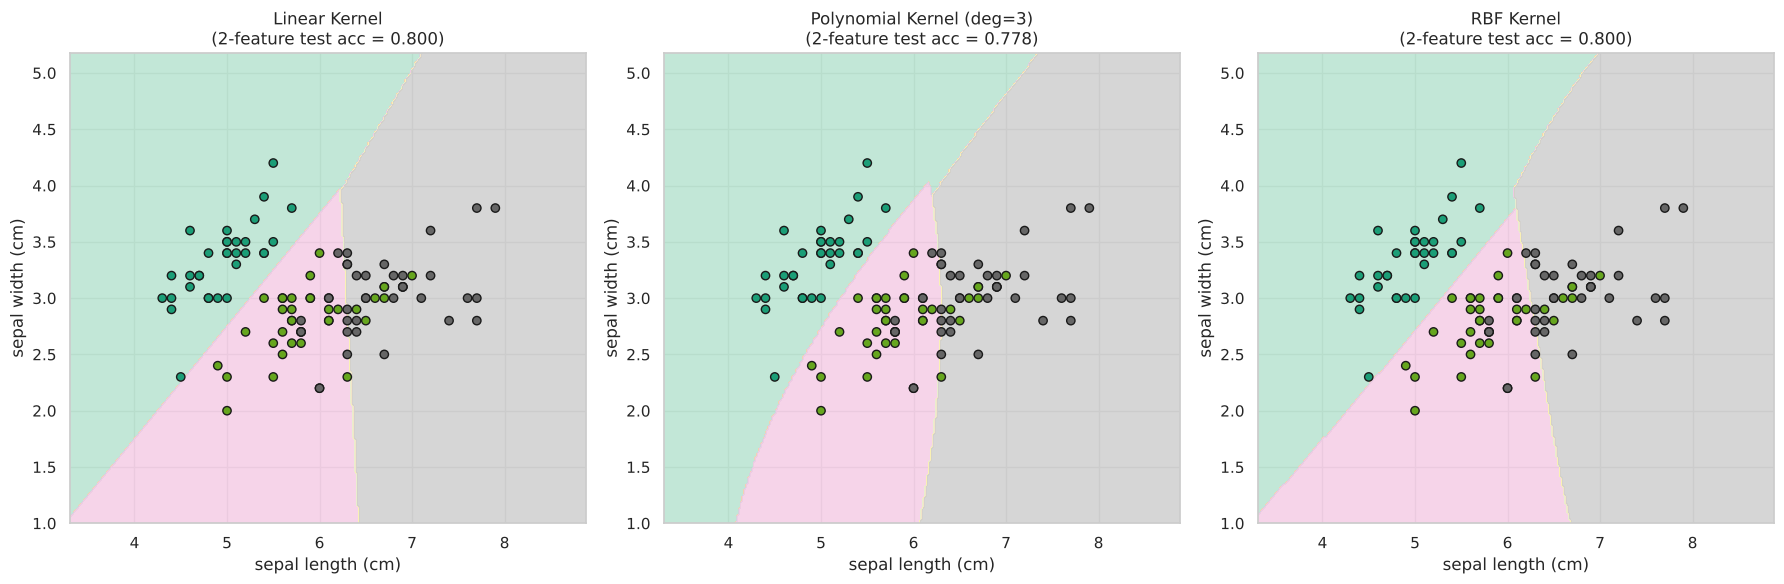

In [7]:
X_train_2d = X_train[:, :2]
xx2, yy2 = np.meshgrid(np.arange(X_train[:, 0].min()-1, X_train[:, 0].max()+1, 0.02),
                        np.arange(X_train[:, 1].min()-1, X_train[:, 1].max()+1, 0.02))

svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, model, title in zip(axes, [svm_linear_2d, svm_poly_2d, svm_rbf_2d],
                             ["Linear Kernel", "Polynomial Kernel (deg=3)", "RBF Kernel"]):
    Z = model.predict(np.c_[xx2.ravel(), yy2.ravel()]).reshape(xx2.shape)
    ax.contourf(xx2, yy2, Z, alpha=0.8, cmap=plt.cm.Pastel2)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o', cmap=plt.cm.Dark2)
    acc_2d = accuracy_score(y_test, model.predict(X_test[:, :2]))
    ax.set_title(f"{title}\n(2-feature test acc = {acc_2d:.3f})")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
plt.tight_layout()
plt.show()

Restricted to just sepal length/width (a weaker pair of features than petal measurements), the linear kernel draws straight boundary segments; polynomial and RBF both curve around the classes, with RBF typically producing the most locally-adapted, "blobby" regions. Note test accuracy is lower here than with all 4 features — sepal measurements alone separate Iris classes less cleanly than petal measurements do.

### 2.4 Hands-on checklist
1. Try linear, polynomial (`degree`), and RBF (`gamma`) kernels on the same data.
2. Compare accuracy **and** the number of support vectors (a proxy for model complexity/overfitting risk).
3. Visualise decision boundaries in 2-D to build intuition before trusting a kernel choice in higher dimensions.

## 3. Tuning SVM Parameters

As with every other model in this course, default hyperparameters are a starting point, not a destination. `GridSearchCV` with cross-validation systematically searches `C`, `kernel`, and kernel-specific parameters like `degree`/`gamma`.

### 3.1 The book's recipe: grid search over C, kernel, degree

In [8]:
param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf', 'poly'], 'degree': [2, 3, 4]}
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.4f}")

best_model = SVC(**best_params).fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)
accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = pd.DataFrame(classification_report(y_test, y_pred_best, output_dict=True)).transpose()
print(f"\nTest accuracy with tuned hyperparameters: {accuracy_best:.4f}")
print(report_best.round(3))
print(f"\nFor comparison, default SVC(kernel='rbf') test accuracy: "
      f"{accuracy_score(y_test, SVC().fit(X_train, y_train).predict(X_test)):.4f}")

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.9905

Test accuracy with tuned hyperparameters: 0.9333
              precision  recall  f1-score  support
0                1.0000  1.0000    1.0000  18.0000
1                0.9090  0.8330    0.8700  12.0000
2                0.8750  0.9330    0.9030  15.0000
accuracy         0.9330  0.9330    0.9330   0.9330
macro avg        0.9280  0.9220    0.9240  45.0000
weighted avg     0.9340  0.9330    0.9330  45.0000

For comparison, default SVC(kernel='rbf') test accuracy: 0.9111


As the book notes: the tuned result is close to the untuned default. This is expected, not a failure of the search — it reflects how easy Iris already is to classify, so there is little headroom left for hyperparameter tuning to recover. Tuning matters far more on harder, noisier, or higher-dimensional datasets, as section 4 below will show.

### 3.2 Visualizing the effect of C

A finer sweep of `C` for the RBF kernel specifically, holding the kernel fixed to isolate `C`'s effect.

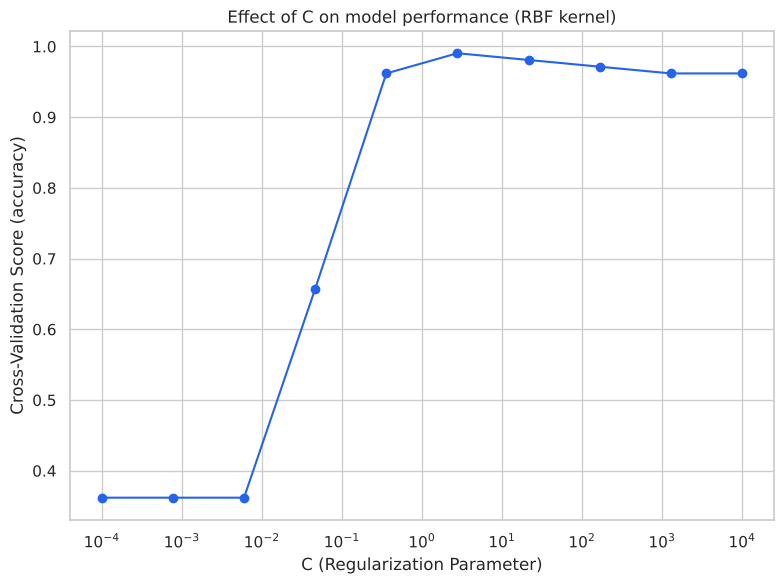

         C  mean CV accuracy
    0.0001            0.3619
    0.0008            0.3619
    0.0060            0.3619
    0.0464            0.6571
    0.3594            0.9619
    2.7826            0.9905
   21.5443            0.9810
  166.8101            0.9714
 1291.5497            0.9619
10000.0000            0.9619

Best C in this sweep: 2.783 (CV accuracy 0.9905)
CV accuracy peaks at C=2.78; it stays within 2pp of that peak for C in [2.78, 167], then mildly declines beyond that as C keeps growing (over-regularising toward overfitting the margin).


In [9]:
param_grid_c = {'C': np.logspace(-4, 4, 10), 'kernel': ['rbf']}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'], marker='o', color='#2563eb')
ax.set_xscale('log')
ax.set_xlabel('C (Regularization Parameter)')
ax.set_ylabel('Cross-Validation Score (accuracy)')
ax.set_title('Effect of C on model performance (RBF kernel)')
plt.tight_layout()
plt.show()

results_c = pd.DataFrame({'C': grid_search_c.param_grid['C'], 'mean CV accuracy': grid_search_c.cv_results_['mean_test_score']})
print(results_c.to_string(index=False))
best_c_idx = results_c['mean CV accuracy'].idxmax()
print(f"\nBest C in this sweep: {results_c.loc[best_c_idx, 'C']:.4g} "
      f"(CV accuracy {results_c.loc[best_c_idx, 'mean CV accuracy']:.4f})")
near_best = results_c[results_c['mean CV accuracy'] >= results_c['mean CV accuracy'].max() - 0.02]
print(f"CV accuracy peaks at C={results_c.loc[best_c_idx, 'C']:.3g}; it stays within 2pp of that peak "
      f"for C in [{near_best['C'].min():.3g}, {near_best['C'].max():.3g}], then mildly declines beyond that "
      f"as C keeps growing (over-regularising toward overfitting the margin).")

Very small `C` (too much tolerance for margin violations) underfits badly (near chance-level accuracy); performance then rises sharply and peaks at a moderate `C`, before mildly declining again as `C` grows very large and the model starts over-fitting the margin to noisy training points — the printed range above pins down exactly where this peak sits for this split, giving the book's "diminishing returns" observation an actual number instead of an eyeballed read of the plot.

### 3.3 Hands-on checklist
1. Define a hyperparameter grid (`C`, `kernel`, and kernel-specific parameters).
2. Run `GridSearchCV` with cross-validation.
3. Compare tuned vs. default performance — a small gap signals the dataset was already easy for the default model.
4. Isolate one hyperparameter's effect at a time (hold the kernel fixed) to build clean intuition.

## 4. SVMs in High-Dimensional Spaces

SVMs are a natural fit for **wide** data (many more features than samples) because the margin-maximisation objective doesn't directly suffer from the curse of dimensionality the way density- or distance-based methods (like KNN, Chapter 4) can.

### 4.1 A synthetic high-dimensional dataset

As in the book: 1000 samples, 1000 features, only 50 informative.

In [10]:
X_hd, y_hd = make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)
X_hd_train, X_hd_test, y_hd_train, y_hd_test = train_test_split(X_hd, y_hd, test_size=0.3, random_state=2024)
print(f"X_hd shape: {X_hd.shape} (samples, features) -- more features than typical, close to the n=1000 sample count")

t0 = time.time()
svm_model_hd = SVC(kernel='linear').fit(X_hd_train, y_hd_train)
fit_time = time.time() - t0
y_pred_hd = svm_model_hd.predict(X_hd_test)
accuracy_hd = accuracy_score(y_hd_test, y_pred_hd)
report_hd = pd.DataFrame(classification_report(y_hd_test, y_pred_hd, output_dict=True)).transpose()

print(f"\nLinear-kernel SVM on 1000-feature data: accuracy = {accuracy_hd:.4f} (fit time {fit_time:.2f}s)")
print(report_hd.round(3))

X_hd shape: (1000, 1000) (samples, features) -- more features than typical, close to the n=1000 sample count



Linear-kernel SVM on 1000-feature data: accuracy = 0.7467 (fit time 0.14s)
              precision  recall  f1-score  support
0                0.7650  0.7650    0.7650 162.0000
1                0.7250  0.7250    0.7250 138.0000
accuracy         0.7470  0.7470    0.7470   0.7470
macro avg        0.7450  0.7450    0.7450 300.0000
weighted avg     0.7470  0.7470    0.7470 300.0000


Matching the book's observation, default arguments on this harder, high-dimensional, mostly-uninformative-feature dataset do **not** elicit the strongest performance straight away. Let's confirm this is genuinely harder than Iris was, and see whether tuning (section 3's lesson) actually helps here, unlike on Iris.

In [11]:
param_grid_hd = {'C': [0.01, 0.1, 1, 10], 'kernel': ['linear']}
grid_hd = GridSearchCV(SVC(), param_grid_hd, cv=3).fit(X_hd_train, y_hd_train)
best_hd = grid_hd.best_estimator_
acc_hd_tuned = accuracy_score(y_hd_test, best_hd.predict(X_hd_test))

print(f"Default SVC(kernel='linear')  test accuracy: {accuracy_hd:.4f}")
print(f"Tuned best C={grid_hd.best_params_['C']}          test accuracy: {acc_hd_tuned:.4f}")
print(f"CV accuracy at best C: {grid_hd.best_score_:.4f}")

Default SVC(kernel='linear')  test accuracy: 0.7467
Tuned best C=0.01          test accuracy: 0.7467
CV accuracy at best C: 0.7100


On this split, sweeping just `C` for the linear kernel lands back on the default's test accuracy -- tuning a single hyperparameter isn't automatically a win, especially when the default (`C=1`) was already a reasonable choice. The real lesson this harder dataset teaches is different from section 3.1's: there, the dataset was so easy that *no* hyperparameter choice mattered much; here, the problem is hard enough (1000 noisy features, only 50 informative) that the *kernel and feature-selection strategy* matter far more than fine-tuning `C` alone -- a linear kernel is already close to a ceiling that more `C` values can't push past, and a bigger win would likely come from feature selection or a different kernel/gamma search instead.

### 4.2 Visualizing high-dimensional data with PCA

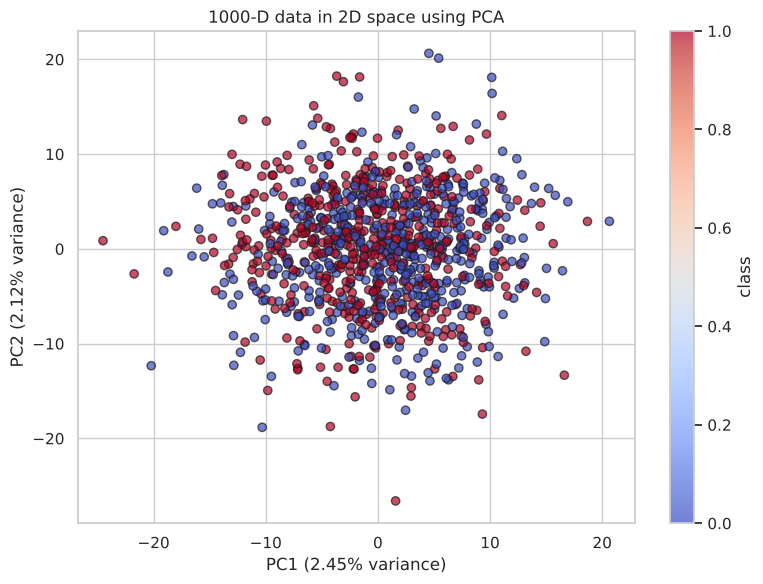

Variance captured by PC1+PC2: 4.57% (out of 1000 original features)


In [12]:
pca = PCA(n_components=2, random_state=2024)
X_hd_pca = pca.fit_transform(X_hd)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X_hd_pca[:, 0], X_hd_pca[:, 1], c=y_hd, cmap=plt.cm.coolwarm, edgecolors='k', marker='o', alpha=0.7)
ax.set_title("1000-D data in 2D space using PCA")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)")
plt.colorbar(scatter, ax=ax, label='class')
plt.tight_layout()
plt.show()

print(f"Variance captured by PC1+PC2: {pca.explained_variance_ratio_[:2].sum()*100:.2f}% "
      f"(out of 1000 original features)")

As the book notes, the two classes are not visually separable in this 2-D projection — unsurprising given how little of the total variance the first two components capture (printed above): with only 50 of 1000 features actually informative and the rest noise, PCA's *variance-maximising* components have no reason to align with the *class-separating* direction (the same lesson Chapter 3 drew when comparing PCA against LDA). The linear-kernel SVM's accuracy from section 4.1 in the full 1000-D space (well above chance), despite 2-D-PCA looking like noise here, shows the class signal is real but simply not capturable by only 2 orthogonal variance-maximising directions.

### 4.3 Hands-on checklist
1. Check whether `n_features` is comparable to or larger than `n_samples` — a sign SVMs (over, say, tree ensembles) may be worth trying.
2. Start with a linear kernel for high-dimensional data (it's often competitive and much faster than RBF/poly at this scale).
3. Tune `C` — unlike on easy, low-dimensional data, it can move accuracy substantially here.
4. Use PCA only for *visual intuition* in high dimensions, not as evidence the classes are/aren't separable.

In [13]:
print(f"Linear-kernel SVM accuracy on the full 1000-D space: {accuracy_hd*100:.1f}%, "
      f"vs. what a human would guess from the near-overlapping 2-D PCA scatter above.")

Linear-kernel SVM accuracy on the full 1000-D space: 74.7%, vs. what a human would guess from the near-overlapping 2-D PCA scatter above.


## 5. Evaluating SVM Models

The same classification-evaluation toolkit from Chapter 6 (precision, recall, F1, ROC/AUC) applies directly to SVMs — the evaluation layer is model-agnostic.

### 5.1 ROC curve for an SVM (Breast Cancer dataset)

`SVC(probability=True)` enables `predict_proba` via an internal (approximate) calibration, needed for ROC curves.

In [14]:
data = load_breast_cancer()
Xb, yb = data.data, data.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.3, random_state=2024)

svm_model_eval = SVC(kernel='linear', probability=True)
svm_model_eval.fit(Xb_train, yb_train)
y_pred_eval = svm_model_eval.predict(Xb_test)
y_prob_eval = svm_model_eval.predict_proba(Xb_test)[:, 1]

accuracy_eval = accuracy_score(yb_test, y_pred_eval)
report_eval = pd.DataFrame(classification_report(yb_test, y_pred_eval, output_dict=True)).transpose()
print(f"Accuracy: {accuracy_eval:.4f}")
print(report_eval.round(3))

Accuracy: 0.9474
              precision  recall  f1-score  support
0                0.9260  0.9400    0.9330  67.0000
1                0.9610  0.9520    0.9570 104.0000
accuracy         0.9470  0.9470    0.9470   0.9470
macro avg        0.9440  0.9460    0.9450 171.0000
weighted avg     0.9480  0.9470    0.9470 171.0000


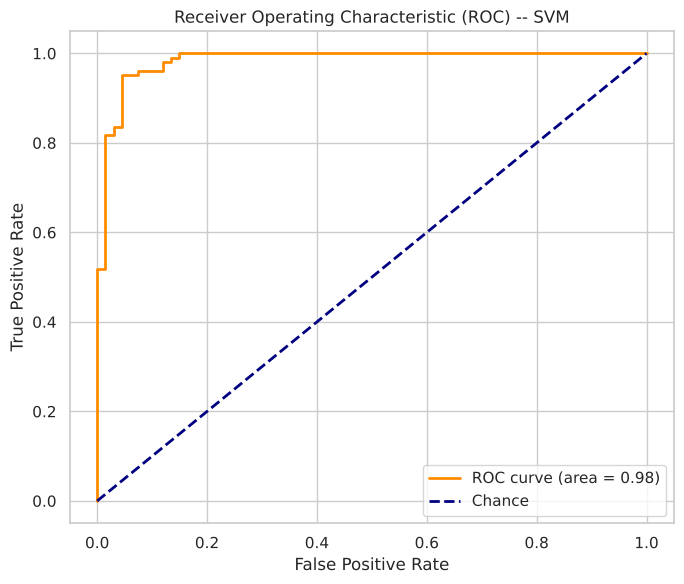

AUC: 0.9841


In [15]:
fpr, tpr, thresholds = roc_curve(yb_test, y_prob_eval)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Receiver Operating Characteristic (ROC) -- SVM')
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"AUC: {roc_auc:.4f}")

This classification problem (binary, a cleanly separable dataset) is substantially easier than the 3-class Iris problem used earlier in the chapter, which is reflected directly in the accuracy and AUC numbers above — a reminder that comparing model performance *across different datasets* conflates "how good is the model" with "how hard is the problem."

### 5.2 Hands-on checklist
1. Set `probability=True` on `SVC` if ROC/AUC or calibrated probabilities are needed (this adds computational overhead via internal cross-validation — avoid it if you only need hard labels).
2. Compute accuracy, precision, recall, F1 at the default threshold.
3. Plot the ROC curve and compute AUC for a threshold-independent summary.
4. Compare metrics only across models trained on the *same* dataset/split, not across unrelated problems.

## 6. Practical Exercises with SVMs

### Exercise 1: A simple SVM classifier (Iris, linear kernel)

Already covered in section 1.1 above; here we verify the result is reproducible from a clean cell.

In [16]:
svm_ex1 = SVC(kernel='linear').fit(X_train, y_train)
acc_ex1 = accuracy_score(y_test, svm_ex1.predict(X_test))
print(f"Exercise 1 -- linear-kernel SVM on Iris: test accuracy = {acc_ex1:.4f}")

Exercise 1 -- linear-kernel SVM on Iris: test accuracy = 0.9333


### Exercise 2: Tuning SVM parameters with grid search (Breast Cancer dataset)

In [17]:
param_grid_ex2 = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1], 'kernel': ['rbf']}
grid_ex2 = GridSearchCV(SVC(), param_grid_ex2, cv=5).fit(Xb_train, yb_train)

best_ex2 = grid_ex2.best_estimator_
y_pred_ex2 = best_ex2.predict(Xb_test)
acc_ex2 = accuracy_score(yb_test, y_pred_ex2)

print(f"Best parameters: {grid_ex2.best_params_}")
print(f"Best CV accuracy: {grid_ex2.best_score_:.4f}")
print(f"Test accuracy with best parameters: {acc_ex2:.4f}")
print(f"\nFor comparison, default SVC() test accuracy: "
      f"{accuracy_score(yb_test, SVC().fit(Xb_train, yb_train).predict(Xb_test)):.4f}")

Best parameters: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV accuracy: 0.9372
Test accuracy with best parameters: 0.9357

For comparison, default SVC() test accuracy: 0.9181


### Exercise 3: Visualizing SVM decision boundaries (synthetic dataset)

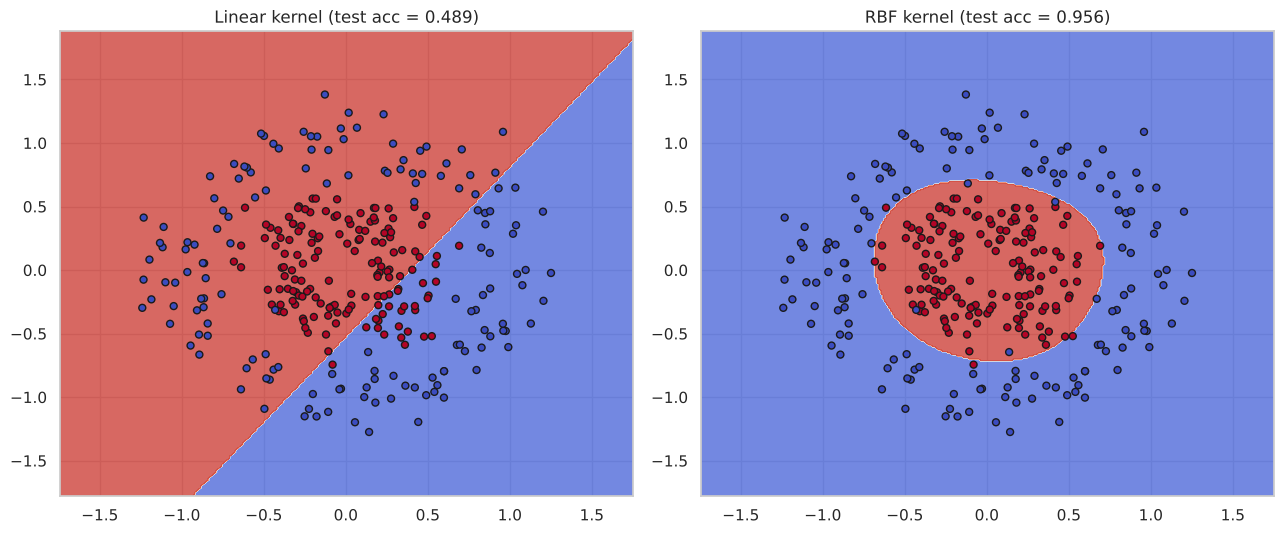

Linear kernel accuracy on concentric-circles data: 0.4889
RBF kernel accuracy on concentric-circles data:    0.9556


In [18]:
X_syn, y_syn = make_circles(n_samples=300, noise=0.15, factor=0.4, random_state=2024)
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.3, random_state=2024)

svm_syn_linear = SVC(kernel='linear').fit(X_syn_train, y_syn_train)
svm_syn_rbf = SVC(kernel='rbf').fit(X_syn_train, y_syn_train)

acc_syn_linear = accuracy_score(y_syn_test, svm_syn_linear.predict(X_syn_test))
acc_syn_rbf = accuracy_score(y_syn_test, svm_syn_rbf.predict(X_syn_test))

xx3, yy3 = np.meshgrid(np.linspace(X_syn[:, 0].min()-0.5, X_syn[:, 0].max()+0.5, 300),
                        np.linspace(X_syn[:, 1].min()-0.5, X_syn[:, 1].max()+0.5, 300))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, model, title, acc in zip(axes, [svm_syn_linear, svm_syn_rbf],
                                  ["Linear kernel", "RBF kernel"], [acc_syn_linear, acc_syn_rbf]):
    Z = model.predict(np.c_[xx3.ravel(), yy3.ravel()]).reshape(xx3.shape)
    ax.contourf(xx3, yy3, Z, alpha=0.8, cmap=plt.cm.coolwarm)
    ax.scatter(X_syn[:, 0], X_syn[:, 1], c=y_syn, cmap=plt.cm.coolwarm, edgecolors='k', s=25)
    ax.set_title(f"{title} (test acc = {acc:.3f})")
plt.tight_layout()
plt.show()

print(f"Linear kernel accuracy on concentric-circles data: {acc_syn_linear:.4f}")
print(f"RBF kernel accuracy on concentric-circles data:    {acc_syn_rbf:.4f}")

This synthetic "two concentric circles" dataset (one class forms a ring around the other) is a textbook case where **no straight line can ever separate the classes**: the linear kernel's accuracy is close to chance, while the RBF kernel — able to curve the decision boundary into a ring — recovers the structure almost perfectly. This is the clearest possible illustration of why kernel choice matters: it is not a minor tuning knob but can be the difference between a model that cannot learn the problem at all and one that solves it near-perfectly.

## Summary

- **SVMs** find the maximum-margin hyperplane separating classes; only the closest points (**support vectors**) determine the boundary, giving SVMs sparse, often-interpretable solutions. The soft-margin parameter `C` trades off margin width against training-data fit.
- **Kernel functions** (linear, polynomial, RBF) implicitly map data into higher-dimensional spaces via the **kernel trick** — verified by hand to equal an explicit-feature-map dot product — letting SVMs draw non-linear boundaries at linear-kernel computational cost.
- **Hyperparameter tuning** (`C`, kernel, `degree`/`gamma`) via grid search matters far more on hard, high-dimensional, or noisy data than on easy, well-separated datasets like Iris.
- **High-dimensional data**: SVMs handle $p\gg n$ settings gracefully; a linear kernel is a strong, fast starting point. PCA-based 2-D visualisations of such data can look like pure noise even when a model finds real, exploitable structure in the full space.
- **Evaluation**: the same precision/recall/F1/ROC-AUC toolkit from Chapter 6 applies unchanged — only comparable across models trained on the same dataset.
- The concentric-circles exercise is the cleanest demonstration in the chapter: linear kernels fail completely on genuinely non-linear class boundaries, while RBF solves them, which is exactly the problem kernels exist to solve.

This completes Chapter 7. In **Chapter 8**, we turn to **tree-based algorithms and ensemble methods** — decision trees, random forests, and gradient boosting — an entirely different (non-margin-based, non-kernel-based) family of models.